In [1]:
%pip install ICIW_Plots
%pip install cma
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime
import pandas as pd
import glob
from scipy.constants import R
from scipy.integrate import solve_ivp
from scipy.signal import correlate, correlation_lags
from pathlib import Path
import sys
import inspect


from AZA_THB_solver import *
from AZA_THB_tools import *
from AZA_THB_reactor_input import *
from AZA_THB_reactor_output_II import *
from AZA_THB_optimizer_II import Optimizer

if 'ICIWstyle' in plt.style.available:
    plt.style.use('ICIWstyle')

Defaulting to user installation because normal site-packages is not writeableNote: you may need to restart the kernel to use updated packages.




[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip

[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Defaulting to user installation because normal site-packages is not writeableNote: you may need to restart the kernel to use updated packages.

['Ar', 'He', 'H2', 'CO', 'CO2', 'CH4', 'H2O', 'CH6', 'C3H8', 'Ne', 'C4', 'C5', 'C6', 'C2en', 'C3en', 'star', 'CO2_s', 'CO_s', 'COin_s', 'CH_s', 'CH2_s', 'O_s', 'H_s', 'HCO_s', 'OH_s', 'H2O_s', 'x', 'H_x', 'HCOO_x', 'OH_x', 'H2O_x']
[[ 0  0 -1  0  0  0  0  0  0  0  0  0  0  0  0 -2  0  0  0  0  0  0  2  0
   0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  1  0 -1  0  0  0  0 -1  1
   0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  1  0  0  0 -1
   0  0  0 -1  0  1  0]
 [ 0  0  0  0  0  1  0  0  0  0  0  0  0  0  0  4  0  0  0 -1  0  0 -3  0
   0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  1  0  0  0  0  0  0 -1  0
   0  0 -1  1  0  0  0]
 [ 0  0  0  0 -1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
   0  0  0 -1  1  0  0]
 [ 0  0  0  0  0  0  0  0  0  0  0  

'-AZA_solver- imported at'

'2026-09-11 10:37:53'

'-AZA_fancy_tools- imported at'

... (3 outputs left out)

'-AZA_THB_reactor_output- imported at'

'2026-09-11 10:37:53'

'-AZA_THB_optimizer- imported at'

'2026-09-11 10:37:53'

In [2]:
# ----------------------------- run selection ---------------------------------
# label -> file path. The order determines the order of the legend.
FILES = {
    '2 bar':             r'Data files\Run_2026-08-05_114101_2bar_150grad_250nml-min_caphsa_reope_ohneMatrix.npy',
    '1 bar':             r'Data files\Run_2026-08-14_115231_1bar_150grad_250nml-min_caphsa_reope_ohneMatrix.npy',
    '2 bar with matrix': r'Data files\Run_2026-07-30_090759_2bar_150grad_250nml-min_caphsa_reope.npy',
}

# NOTE: there is no "1 bar with matrix" run. With three of four combinations
# the pressure effect and the matrix effect cannot be separated cleanly.
# Either add the measurement or state it as a limitation in the report.

KERNEL_NAME = ['E1  inlet piping', 'E2  reactor',
               'E3  outlet piping', 'E4  capillary']


In [3]:
"""
===============================================================================
 Shared helpers: loading, moments, and the diagnostics used in Section 4.2
===============================================================================

CONVENTION  (state this once in the report)
-------------------------------------------
    sigma    standard deviation of the RTD          [s]
    sigma^2  variance of the RTD                    [s^2]

Stagge et al. (2026) denote the VARIANCE by sigma and list it in s^2
(Nomenclature and eq. 24). The symbol therefore means different things in
this script and in the reference. Define your convention explicitly in the
report, otherwise the numbers cannot be compared.

WHAT THE DIAGNOSTICS ARE FOR
----------------------------
1) Normalisation condition, int E_i dt = 1  (Stagge et al. 2026, eq. 22)
   This is the mass-conservation check. It is NOT part of the training loss,
   so a deviation is independent evidence about fit quality. Report the raw
   value per kernel, before normalisation.

2) Additivity of the moments
   For compartments in series the variances add:
       sigma_tot^2 = sum_i sigma_i^2
   The total kernel here is BUILT by convolution, so exact agreement is
   expected on an ideal grid. Any residual gap is numerical, and its most
   likely source is kernel truncation: the second moment is weighted by t^2,
   so a window that cuts the tail systematically UNDERESTIMATES sigma^2.
   A gap that is negative for every case is the signature of that.

3) Truncation indicators
   - edge_start / edge_end: kernel value at the window boundary, relative to
     the peak. A non-zero value means the window is too narrow. A sharp peak
     at the end of the window is the same symptom and vanishes for longer
     kernel times (Stagge et al. 2026, Section 4.2).
   - trapz vs sum normalisation: np.trapezoid half-weights the end points,
     np.convolve does not. If a kernel is non-zero at its boundary the two
     normalisations disagree, and mass is lost or gained in the cascade.
===============================================================================
"""
import numpy as np

# np.trapezoid exists from NumPy 2.0; fall back for older installations.
_trapz = getattr(np, 'trapezoid', None) or np.trapz


def _to_dict(obj):
    """np.load returns either a 0-d array or a dict, depending on how it was saved."""
    return obj.item() if isinstance(obj, np.ndarray) and obj.ndim == 0 else obj


def _moments(t, E):
    """First moment tau [s] and standard deviation sigma [s] of a normalised kernel."""
    tau = float(_trapz(t * E, t))
    var = float(_trapz((t - tau) ** 2 * E, t))
    return tau, float(np.sqrt(max(var, 0.0)))


def kernel_diagnostics(t, E):
    """Everything needed to judge whether a kernel is usable.

    Returns a dict with the raw integral (normalisation condition), the two
    competing normalisations, the relative boundary values and the moments of
    the normalised kernel.
    """
    t = np.asarray(t, float)
    E = np.asarray(E, float)

    step = np.diff(t)
    if not np.allclose(step, step[0], rtol=1e-9, atol=1e-12):
        raise ValueError('kernel has a non-uniform time grid')
    dt = float(step[0])

    area_trapz = float(_trapz(E, t))          # Stagge et al. eq. 22
    area_sum = float(E.sum() * dt)            # what np.convolve implicitly assumes
    peak = float(np.max(np.abs(E))) or 1.0

    En = E / area_trapz
    tau, sigma = _moments(t, En)

    return {
        't': t, 'E': En, 'dt': dt,
        'area_raw': area_trapz,                       # report this one
        'area_sum': area_sum,
        'area_mismatch': area_sum / area_trapz - 1.0,  # trapz vs sum
        'edge_start': float(E[0]) / peak,              # 0 = clean, >0.01 = window too narrow
        'edge_end': float(E[-1]) / peak,
        't_span': float(t[-1] - t[0]),
        'tau': tau, 'sigma': sigma,
    }


def load_kernels(path):
    """Load the four compartment kernels of one training run, with diagnostics."""
    d = _to_dict(np.load(path, allow_pickle=True))
    return [kernel_diagnostics(t, E) for t, E in zip(d['ts'], d['Es'])]


def print_kernel_table(runs, kernel_name, edge_tol=0.01, area_tol=0.01):
    """Normalisation condition, moments and truncation flags, per run and stage.

    edge_tol   boundary value above this fraction of the peak is flagged
    area_tol   |int E dt - 1| above this is flagged
    """
    n_k = min(len(v) for v in runs.values())

    print('=' * 100)
    print('Kernel diagnostics   (sigma = standard deviation in s)')
    print('=' * 100)
    header = f'{"run":22s} {"stage":22s} {"int E dt":>9s} {"tau / s":>9s} ' \
             f'{"sigma / s":>10s} {"sigma^2 / s^2":>13s} {"edge0":>7s} {"edgeN":>7s}  flags'
    print(header)
    print('-' * 100)

    flagged = []
    for name, ks in runs.items():
        for i in range(n_k):
            k = ks[i]
            flags = []
            if abs(k['area_raw'] - 1.0) > area_tol:
                flags.append('NORM')
            if k['edge_start'] > edge_tol:
                flags.append('CUT-START')
            if k['edge_end'] > edge_tol:
                flags.append('CUT-END')
            if abs(k['area_mismatch']) > 1e-3:
                flags.append('TRAPZ/SUM')
            if flags:
                flagged.append((name, kernel_name[i], flags))
            print(f'{name:22s} {kernel_name[i]:22s} {k["area_raw"]:9.4f} '
                  f'{k["tau"]:9.2f} {k["sigma"]:10.2f} {k["sigma"] ** 2:13.2f} '
                  f'{k["edge_start"]:7.3f} {k["edge_end"]:7.3f}  {" ".join(flags)}')
        print('-' * 100)

    print()
    print('int E dt   normalisation condition, Stagge et al. 2026 eq. 22. Target 1.')
    print('edge0/N    kernel value at the window boundary, relative to the peak.')
    print('           A value clearly above 0 means t_E^end (or the start) is too tight;')
    print('           the tail is cut and sigma^2 is underestimated.')
    if flagged:
        print()
        print('FLAGGED - these have to be addressed or explained in the report:')
        for name, stage, flags in flagged:
            print(f'   {name:22s} {stage:22s} {", ".join(flags)}')
    else:
        print()
        print('No kernel flagged: normalisation and window width are unproblematic.')
    print()


def print_additivity_check(runs, totals, kernel_name):
    """Variance additivity: sum of the stage variances against the total.

    For a series arrangement the variances add. This is the independent check,
    because the moments never entered the training loss. Report it in the text;
    a stacked bar chart of the variance SHARES cannot show it, since those
    shares are normalised to the sum and are consistent by construction.
    """
    n_k = min(len(v) for v in runs.values())

    print('=' * 100)
    print('Moment additivity   sigma_tot^2  vs.  sum_i sigma_i^2')
    print('=' * 100)
    print(f'{"run":22s} {"sum sigma_i^2":>14s} {"sigma_tot^2":>13s} {"deviation":>11s} '
          f'{"sum tau_i":>11s} {"tau_tot":>9s} {"deviation":>11s}')
    print('-' * 100)

    devs = []
    for name, ks in runs.items():
        var_sum = sum(k['sigma'] ** 2 for k in ks[:n_k])
        tau_sum = sum(k['tau'] for k in ks[:n_k])
        var_tot = totals[name]['sigma'] ** 2
        tau_tot = totals[name]['tau']
        d_var = var_sum / var_tot - 1.0
        d_tau = tau_sum / tau_tot - 1.0
        devs.append(d_var)
        print(f'{name:22s} {var_sum:14.2f} {var_tot:13.2f} {d_var * 100:10.1f} % '
              f'{tau_sum:11.2f} {tau_tot:9.2f} {d_tau * 100:10.1f} %')
    print('-' * 100)
    print()

    if devs and all(d < -1e-3 for d in devs):
        print('The sum lies BELOW the total in every case. That is systematic, not scatter.')
        print('Most likely cause: kernel truncation. sigma^2 weights the tail with t^2, so')
        print('a window that is too short underestimates it. Check the CUT-END flags above,')
        print('then repeat the training with a longer t_E^end and see whether the gap closes.')
    elif devs and all(d > 1e-3 for d in devs):
        print('The sum lies ABOVE the total in every case - check the normalisation of the')
        print('total kernel and the trapz/sum mismatch flagged above.')
    else:
        print('No systematic direction in the deviation; the residual is numerical.')
    print()


Overall RTD   E1 (x) E2 (x) E3 (x) E4        alignment: onset
run                      tau / s  sigma / s sigma^2 / s^2   t50 / s  t10-90 / s  dead time  sigma/tau     shift
----------------------------------------------------------------------------------------------------
2 bar                      45.28       4.57         20.89     43.83       10.13      39.88     0.1010   -39.88s
1 bar                      27.39       4.13         17.05     26.16        9.14      22.28     0.1508   -22.28s
2 bar with matrix          45.14       4.32         18.64     43.74        9.22      40.27     0.0956   -40.27s
----------------------------------------------------------------------------------------------------
sigma/tau is the dimensionless spread: small means close to plug flow.
It is independent of the dead time and therefore the fairest comparison
between runs with different dead volume.

Kernel diagnostics   (sigma = standard deviation in s)
run                    stage                   i

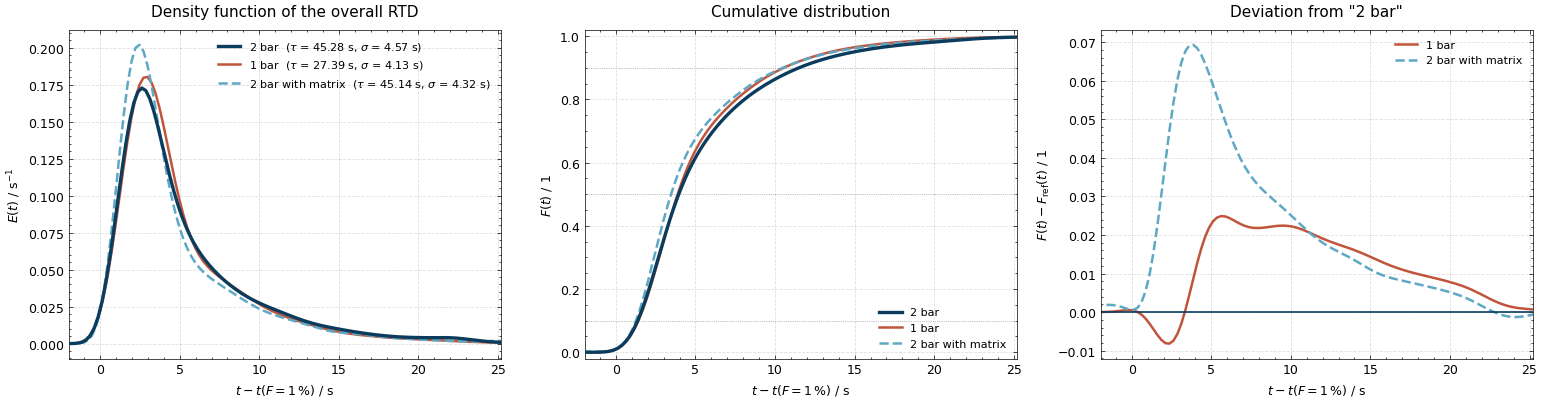

In [4]:
"""
===============================================================================
 Figure 1: overall residence time distribution  E1 (x) E2 (x) E3 (x) E4
===============================================================================

WHAT CHANGED RELATIVE TO THE PREVIOUS VERSION
---------------------------------------------
- Labels in English (the report is in English).
- The reference case is now the prominent line. Previously the reference was
  grey and dashed, i.e. it read as the least important curve.
- Third panel: dF = F_case - F_reference. The F curves lie almost on top of
  each other, so the raw comparison carries little information. The difference
  makes the effect of pressure and matrix readable and gives a number for the
  text instead of "nearly identical".
- Normalisation condition and moment additivity are printed, not plotted.
  Those two are the independent quality criteria for Section 4.2.
- tau is reported in the legend as well, so the information destroyed by the
  onset alignment stays visible.

MISSING CASE
------------
There is no "1 bar with matrix" run. With three of four combinations the
effects of pressure and matrix cannot be separated cleanly. Either add the
measurement or state this as a limitation in the report.
===============================================================================
"""
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------- settings ------------------------------------
REFERENCE = '2 bar'      # gets the prominent line; must be a key of FILES

ALIGN = 'onset'          # 'onset' | 't50' | 'tau' | 'none'
ONSET_LEVEL = 0.01       # F(t) = 1 % counts as the start
T_MAX = None             # axis end in s; None = automatic
SHOW_DELTA_F = True      # third panel with F_case - F_reference
SAVE_AS = None           # e.g. 'total_rtd.pdf' - use a vector format
# -----------------------------------------------------------------------------

# Reference: solid, dark, thick. Others: thinner, distinguishable in greyscale
# as well, because line style carries the distinction and not colour alone.
STYLE_REF = dict(color='#0B3C5D', linestyle='-', lw=2.4, zorder=3)
STYLE_OTHERS = [dict(color='#C1553B', linestyle='-', lw=1.8, zorder=2),
                dict(color='#5FA8C4', linestyle='--', lw=1.8, zorder=2),
                dict(color='#7A8B99', linestyle=':', lw=1.8, zorder=2)]


def load_total_rtd(path, onset_level=ONSET_LEVEL):
    """Chain E1..E4 into the overall RTD.

    Convolving the kernels first and only then applying a signal is equivalent
    by associativity, but numerically cleaner: only one boundary effect arises.

    The factor dt appears because np.convolve forms a sum while the convolution
    is an integral:  int f(t') g(t-t') dt'  ~  sum * dt.
    """
    ks = load_kernels(path)

    dts = [k['dt'] for k in ks]
    if not np.allclose(dts, dts[0], rtol=1e-9, atol=1e-12):
        raise ValueError(f'{path}: kernels have different dt: {dts}')
    dt = float(dts[0])

    E_tot = ks[0]['E']
    for k in ks[1:]:
        E_tot = np.convolve(E_tot, k['E']) * dt

    t_tot = np.arange(E_tot.size) * dt
    E_tot = E_tot / _trapz(E_tot, t_tot)

    F = np.concatenate(([0.0], np.cumsum(0.5 * (E_tot[1:] + E_tot[:-1]) * dt)))
    F = F / F[-1]

    tau, sigma = _moments(t_tot, E_tot)

    return {'t': t_tot, 'E': E_tot, 'F': F, 'dt': dt,
            'tau': tau, 'sigma': sigma,
            't50': float(np.interp(0.50, F, t_tot)),
            't10': float(np.interp(0.10, F, t_tot)),
            't90': float(np.interp(0.90, F, t_tot)),
            't_onset': float(np.interp(onset_level, F, t_tot)),
            'kernels': ks}


def shift_of(r, mode=ALIGN):
    """Time shift that puts the chosen reference point at t = 0."""
    return {'onset': r['t_onset'], 't50': r['t50'], 'tau': r['tau']}.get(mode, 0.0)


def style_for(name, index):
    if name == REFERENCE:
        return dict(STYLE_REF)
    others = [n for n in FILES if n != REFERENCE]
    return dict(STYLE_OTHERS[others.index(name) % len(STYLE_OTHERS)])


# ================================ computation ================================
res = {name: load_total_rtd(path) for name, path in FILES.items()}
runs = {name: r['kernels'] for name, r in res.items()}

if REFERENCE not in res:
    raise KeyError(f'REFERENCE = {REFERENCE!r} is not a key of FILES: {list(FILES)}')

label_x = {'onset': f'$t - t(F = {ONSET_LEVEL * 100:.0f}\\,\\%)$ / s',
           't50': '$t - t_{50}$ / s',
           'tau': r'$t - \tau$ / s',
           'none': '$t$ / s'}[ALIGN]

print('=' * 100)
print(f'Overall RTD   E1 (x) E2 (x) E3 (x) E4        alignment: {ALIGN}')
print('=' * 100)
print(f'{"run":22s} {"tau / s":>9s} {"sigma / s":>10s} {"sigma^2 / s^2":>13s} '
      f'{"t50 / s":>9s} {"t10-90 / s":>11s} {"dead time":>10s} {"sigma/tau":>10s} {"shift":>9s}')
print('-' * 100)
for name, r in res.items():
    print(f'{name:22s} {r["tau"]:9.2f} {r["sigma"]:10.2f} {r["sigma"] ** 2:13.2f} '
          f'{r["t50"]:9.2f} {r["t90"] - r["t10"]:11.2f} {r["t_onset"]:10.2f} '
          f'{r["sigma"] / r["tau"]:10.4f} {-shift_of(r):8.2f}s')
print('-' * 100)
print('sigma/tau is the dimensionless spread: small means close to plug flow.')
print('It is independent of the dead time and therefore the fairest comparison')
print('between runs with different dead volume.')
print()

# --- the two independent checks for Section 4.2 ---
print_kernel_table(runs, KERNEL_NAME)
print_additivity_check(runs, res, KERNEL_NAME)

# --- differences against the reference, as numbers for the text ---
ref = res[REFERENCE]
print('=' * 100)
print(f'Differences against the reference case "{REFERENCE}"')
print('=' * 100)
print(f'{"run":22s} {"d tau / s":>10s} {"d sigma / s":>12s} {"d t50 / s":>10s} '
      f'{"d sigma / %":>12s}')
print('-' * 100)
for name, r in res.items():
    if name == REFERENCE:
        continue
    print(f'{name:22s} {r["tau"] - ref["tau"]:10.2f} {r["sigma"] - ref["sigma"]:12.2f} '
          f'{r["t50"] - ref["t50"]:10.2f} {(r["sigma"] / ref["sigma"] - 1) * 100:11.1f} %')
print()

# ================================== plot =====================================
n_panels = 3 if SHOW_DELTA_F else 2
fig, axes = plt.subplots(1, n_panels, figsize=(5.2 * n_panels, 4.2))

for i, (name, r) in enumerate(res.items()):
    t = r['t'] - shift_of(r)
    st = style_for(name, i)
    lbl = f'{name}  ($\\tau$ = {r["tau"]:.2f} s, $\\sigma$ = {r["sigma"]:.2f} s)'
    axes[0].plot(t, r['E'], label=lbl, **st)
    axes[1].plot(t, r['F'], label=name, **st)

# --- panel 1: density function ---
axes[0].set_xlabel(label_x)
axes[0].set_ylabel(r'$E(t)$ / s$^{-1}$')
axes[0].set_title('Density function of the overall RTD', fontsize=11)
axes[0].legend(fontsize=8, frameon=False)
axes[0].grid(alpha=0.25, lw=0.6)

# --- panel 2: cumulative distribution with 10 / 50 / 90 % guides ---
for lvl in (0.1, 0.5, 0.9):
    axes[1].axhline(lvl, color='gray', lw=0.5, ls=':')
axes[1].set_xlabel(label_x)
axes[1].set_ylabel(r'$F(t)$ / 1')
axes[1].set_ylim(-0.02, 1.02)
axes[1].set_title('Cumulative distribution', fontsize=11)
axes[1].legend(fontsize=8, frameon=False, loc='lower right')
axes[1].grid(alpha=0.25, lw=0.6)

# --- panel 3: difference against the reference ---
# The F curves are nearly congruent, so the raw comparison carries little
# information. The difference resolves it and yields a number for the text.
if SHOW_DELTA_F:
    t_ref = ref['t'] - shift_of(ref)
    for i, (name, r) in enumerate(res.items()):
        if name == REFERENCE:
            continue
        t = r['t'] - shift_of(r)
        F_on_ref = np.interp(t_ref, t, r['F'], left=0.0, right=1.0)
        st = style_for(name, i)
        axes[2].plot(t_ref, F_on_ref - ref['F'], label=name, **st)

    axes[2].axhline(0, color='#0B3C5D', lw=1.2)
    axes[2].set_xlabel(label_x)
    axes[2].set_ylabel(r'$F(t) - F_\mathrm{ref}(t)$ / 1')
    axes[2].set_title(f'Deviation from "{REFERENCE}"', fontsize=11)
    axes[2].legend(fontsize=8, frameon=False)
    axes[2].grid(alpha=0.25, lw=0.6)

# --- common axis limits ---
# right: until every curve has reached F = 99.5 %
# left: only a small margin before the reference point, otherwise the axis
# reaches back to -tau and the interesting region is pushed to the right edge.
t_end = (max(np.interp(0.995, r['F'], r['t']) - shift_of(r) for r in res.values())
         if T_MAX is None else T_MAX)
t_raw = min((r['t'] - shift_of(r))[0] for r in res.values())
t_start = 0.0 if ALIGN == 'none' else max(t_raw, -0.08 * t_end)
for ax in axes:
    ax.set_xlim(t_start, t_end * 1.03)

plt.tight_layout()
if SAVE_AS:
    plt.savefig(SAVE_AS, dpi=300, bbox_inches='tight')
    print(f'saved: {SAVE_AS}')
plt.show()


Individual kernels: moments per stage   (sigma = standard deviation in s)
run                                  E1               E2               E3               E4
----------------------------------------------------------------------------------------------------
2 bar                     14.60 /  1.40    16.53 /  3.48    11.82 /  0.73     2.26 /  2.25      (tau / sigma in s)
1 bar                      7.94 /  1.69     6.75 /  2.71    10.44 /  1.28     2.24 /  2.19      (tau / sigma in s)
2 bar with matrix         16.64 /  1.60    13.29 /  3.28    12.93 /  0.43     2.25 /  2.15      (tau / sigma in s)
----------------------------------------------------------------------------------------------------

Stage-wise change of the dispersion against "2 bar"
run                                E1             E2             E3             E4
----------------------------------------------------------------------------------------------------
1 bar                          21.1 %        -22.1 

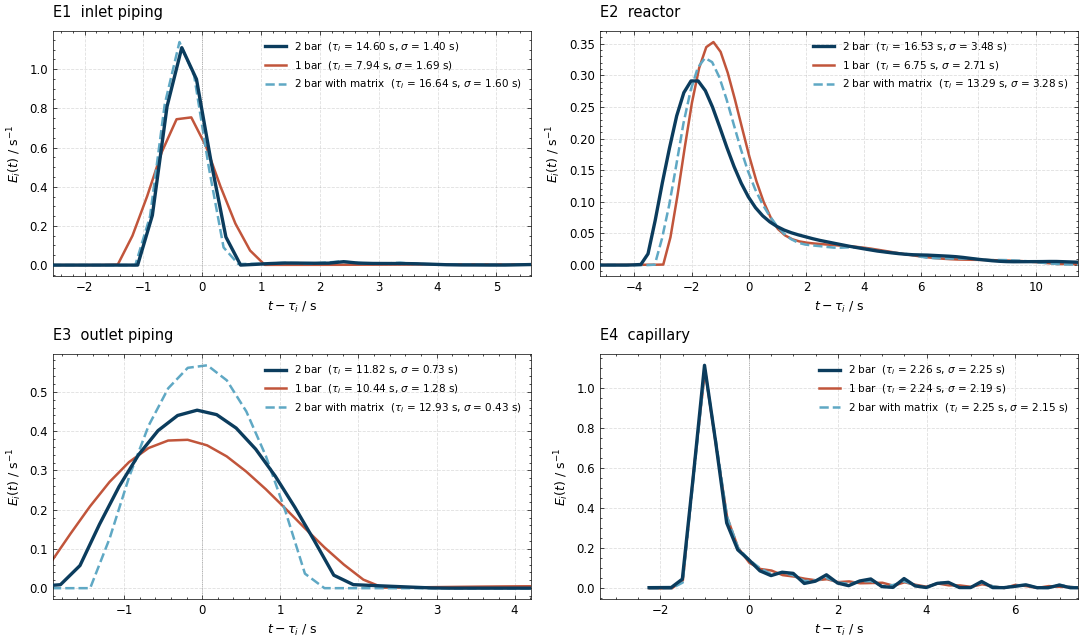

In [ ]:
"""
===============================================================================
 Figure 2: individual kernels E1 to E4
===============================================================================

"""
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------- settings ------------------------------------
KERNEL_NAME = ['E1  inlet piping', 'E2  reactor',
               'E3  outlet piping', 'E4  capillary']

REFERENCE = '2 bar'      # gets the prominent line; must be a key of FILES

ALIGN_SINGLE = 'tau'     # 'tau' = shift onto the expectation value, 'none' = absolute
X_PAD = 1.5              # window width as a multiple of sigma (only for 'tau')
ANNOTATE_DIRAC = True    # note on the E4 peak
DIRAC_STAGE = 3          # index of the capillary stage
SAVE_AS = None           # e.g. 'kernels.pdf' - use a vector format
# -----------------------------------------------------------------------------

STYLE_REF = dict(color='#0B3C5D', linestyle='-', lw=2.4, zorder=3)
STYLE_OTHERS = [dict(color='#C1553B', linestyle='-', lw=1.8, zorder=2),
                dict(color='#5FA8C4', linestyle='--', lw=1.8, zorder=2),
                dict(color='#7A8B99', linestyle=':', lw=1.8, zorder=2)]


def style_for(name):
    if name == REFERENCE:
        return dict(STYLE_REF)
    others = [n for n in FILES if n != REFERENCE]
    return dict(STYLE_OTHERS[others.index(name) % len(STYLE_OTHERS)])


# ================================ computation ================================
runs = {name: load_kernels(path) for name, path in FILES.items()}
n_k = min(len(v) for v in runs.values())

print('=' * 100)
print('Individual kernels: moments per stage   (sigma = standard deviation in s)')
print('=' * 100)
print(f'{"run":22s} ' + ' '.join(f'{KERNEL_NAME[i].split()[0]:>16s}' for i in range(n_k)))
print('-' * 100)
for name, ks in runs.items():
    cells = ' '.join(f'{k["tau"]:8.2f} /{k["sigma"]:6.2f}' for k in ks[:n_k])
    print(f'{name:22s} {cells}      (tau / sigma in s)')
print('-' * 100)
print()

# --- stage-wise comparison against the reference: this is where the story is ---
ref_ks = runs[REFERENCE]
print('=' * 100)
print(f'Stage-wise change of the dispersion against "{REFERENCE}"')
print('=' * 100)
print(f'{"run":22s} ' + ' '.join(f'{KERNEL_NAME[i].split()[0]:>14s}' for i in range(n_k)))
print('-' * 100)
for name, ks in runs.items():
    if name == REFERENCE:
        continue
    cells = ' '.join(f'{(ks[i]["sigma"] / ref_ks[i]["sigma"] - 1) * 100:12.1f} %'
                     for i in range(n_k))
    print(f'{name:22s} {cells}')
print('-' * 100)
print()

# ================================== plot =====================================
fig, axs = plt.subplots(2, 2, figsize=(11, 6.6))
axes = axs.ravel()

for name, ks in runs.items():
    st = style_for(name)
    for i in range(n_k):
        k = ks[i]
        # Shifting onto the expectation value puts the curves on top of each
        # other and makes the width difference directly visible.
        t = k['t'] - (k['tau'] if ALIGN_SINGLE == 'tau' else 0.0)
        lbl = (f'{name}  ($\\tau_i$ = {k["tau"]:.2f} s, $\\sigma$ = {k["sigma"]:.2f} s)'
               if ALIGN_SINGLE == 'tau' else
               f'{name}  ($\\sigma$ = {k["sigma"]:.2f} s)')
        axes[i].plot(t, k['E'], label=lbl, **st)

for i in range(n_k):
    ax = axes[i]
    ax.set_title(KERNEL_NAME[i], fontsize=10.5, loc='left')
    ax.set_ylabel(r'$E_i(t)$ / s$^{-1}$', fontsize=9)
    ax.set_xlabel(r'$t - \tau_i$ / s' if ALIGN_SINGLE == 'tau' else '$t$ / s', fontsize=9)
    ax.legend(fontsize=7.5, frameon=False)
    ax.grid(alpha=0.25, lw=0.6)
    ax.tick_params(labelsize=8.5)

    if ALIGN_SINGLE == 'tau':
        # Derive the window width per panel from the widest curve of that stage.
        # One fixed value for all four panels clips the wide kernels and makes
        # the narrow ones look lost.
        sig_max = max(ks[i]['sigma'] for ks in runs.values())
        span = max(sig_max, 0.6)
        ax.set_xlim(-X_PAD * span, X_PAD * span * 2.2)   # right-skewed: more room right
        ax.axvline(0, color='gray', lw=0.5, ls=':')



plt.tight_layout()
if SAVE_AS:
    plt.savefig(SAVE_AS, dpi=300, bbox_inches='tight')
    print(f'saved: {SAVE_AS}')
plt.show()
